# Power Query v Pythonu: od importu k analýze a vizualizaci

**Jupyter notebook pro kurz Zpracování dat**  
**Návaznost:** PL02 (import) → PL03 (kvalita) → PL04 (spojení, Pivot/Unpivot) → PL05 (statistika) → PL06 (interpretace).

Tento notebook **převádí principy Power Query do Pythonu** pomocí knihoven **pandas**, **NumPy** a **Matplotlib**. Používá původní syntetická data kurzu a dva malé příklady z prezentací: **násobení řádků při JOIN** a **široká versus dlouhá tabulka**.

> **Výukový cíl:** ne pouze vykreslit graf, ale v každé fázi vědět, *co znamená jeden řádek, jaká je jednotka hodnot, jaká operace změnila počet řádků a jak správnost ověřit*.

## Mapa lekcí a vazba na Power Query

| Power Query / M | Python / pandas | Kde v notebooku |
|---|---|---|
| Z textu/CSV, Ze složky, Z JSON | `read_csv`, `glob`, `concat`, `json_normalize` | A |
| `Table.RowCount`, `Table.ColumnCount` | `len(df)`, `df.shape[1]` | A |
| Odkaz (Reference) na dotaz | `df.copy()` a odvozené proměnné | B |
| Odebrat duplicity, Nahradit hodnoty, Vlastní sloupec | `drop_duplicates`, `replace`, `assign` | B |
| Karanténa a validace | booleovské masky, seznam důvodů | B |
| Autorizované opravy | kontrolovaná aktualizace podle ID | C |
| Připojit dotazy (Append) | `pd.concat` | D |
| Sloučit dotazy (Merge) | `pd.merge`, `validate`, `_merge` | D–E |
| Složený klíč | `on=[...]` | E |
| Kontingenční sloupec / Pivot | `pivot`, `pivot_table` | F |
| Převést sloupce na řádky / Unpivot | `melt` | F |
| Seskupit podle, sumy, podíl | `groupby().agg()` | G |
| Histogram a boxplot | `matplotlib` | H |

**Pozor:** Automatické převody typů, práce s `null` a některé detaily Pivot/Unpivot se v pandas a Power Query liší (viz komentáře u konkrétních kroků).

---
# A. Import dat a kontrola struktury (PL02)

Nejprve **čteme surové CSV bez převodu identifikátorů na čísla**. Nepřepisujeme originál a neodstraňujeme problematické hodnoty při importu.

In [ ]:
%pip install matplotlib

In [ ]:
from pathlib import Path
from collections import Counter
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# kontrola existence datového souboru
ROOT = Path.cwd()
DATA = ROOT / "data"
if not (DATA / "raw" / "provoz_2025.csv").exists():
    raise FileNotFoundError(
        "Chybí data/raw/provoz_2025.csv. Otevřete notebook z rozbaleného ZIPu; "
        "soubor a adresář data musí zůstat vedle sebe."
    )
OUT = ROOT / "vystupy"
OUT.mkdir(exist_ok=True)

# matplotlib Runtime Configuration
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.20
# pandas Runtime Configuration
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 130)
print("Datová složka:", DATA.resolve())
print("pandas:", pd.__version__)

Datová složka: D:\Dokumenty\Dropbox\UJEP\prog\_MSW2\Data2\data
pandas: 3.1.1


### A1. Surový CSV – kontrola řádků, sloupců a posledního ID

**Power Query:** `Data → Z textu/CSV`, UTF-8, oddělovač středník, všech sedm sloupců nejprve jako text.  
**Python:** `read_csv(..., sep=";", dtype="string", keep_default_na=False)`; chybějící text zůstane prázdným řetězcem a nenahradí se předčasně nulou.

In [7]:
# dataframe
raw = pd.read_csv(
    DATA / "raw" / "provoz_2025.csv",
    sep=";", encoding="utf-8-sig", dtype="string", keep_default_na=False
)

expected_columns = [
    "zaznam_id", "mesic", "pobocka_id", "sluzba",
    "pocet_zasilek", "pocet_zpozdenych", "naklady_kc"
]

# nový dataframe pro kontrolu importu
kontrola_importu = pd.DataFrame({
    "Kontrola": ["Počet řádků", "Počet sloupců", "První ID", "Poslední fyzické ID", "Správné záhlaví"],
    "Výsledek": [len(raw), raw.shape[1], raw.iloc[0]["zaznam_id"],
                raw.iloc[-1]["zaznam_id"], list(raw.columns) == expected_columns]
})

# výpis obou tabulek
display(kontrola_importu, raw.head(5))      # prvních 5 řádků

# kontrola importu (pokud podmínka není splněna, vyhodí chybu)
assert raw.shape == (149, 7)
assert raw.iloc[0]["zaznam_id"] == "R001"
assert raw.iloc[-1]["zaznam_id"] == "R112"
assert list(raw.columns) == expected_columns

,Kontrola,Výsledek
0,Počet řádků,149
1,Počet sloupců,7
2,První ID,R001
3,Poslední fyzické ID,R112
4,Správné záhlaví,True


,zaznam_id,mesic,pobocka_id,sluzba,pocet_zasilek,pocet_zpozdenych,naklady_kc
0,R001,2025-01,B01,standard,854,20,"30807,16"
1,R002,2025-01,B01,EXPRESS,332,9,"17990,18"
2,R003,2025-01,B02,standard,348,21,"12660,9"
3,R004,2025-01,b02,expres,142,9,"7739,57"
4,R005,2025-01,B03,Std,605,18,"21885,16"


### A2. Import dvanácti měsíčních CSV – obdoba „Kombinovat a transformovat“

Každý soubor načteme jako samostatnou tabulku, přidáme informaci o zdroji a spojíme **řádky pod sebe**. Porovnáme *obsah i četnosti celých řádků*: stejný počet 149 sám o sobě nestačí.

In [4]:
# .glob("*.csv") vyhledá v cílové složce všechny soubory .csv (metoda Pathlib.Path.glob)
files = sorted((DATA / "raw" / "mesice").glob("*.csv"))
assert len(files) == 12         # kontrola, že je načteno 12 souborů (1 soubor pro každý měsíc)
monthly_parts = []              # seznam pro načtení jednotlivých měsíců

for file in files:
    part = pd.read_csv(file, sep=";", encoding="utf-8-sig",
                       dtype="string", keep_default_na=False)
    part["_zdrojovy_soubor"] = file.name    # přidá další sloupec s názvem souboru, ze kterého byl importován
    monthly_parts.append(part)

# sloučení všech načtených měsíců do jednoho dataframe
monthly_with_source = pd.concat(monthly_parts, ignore_index=True)
# odstranění pomocného sloupce s názvem souboru, aby se porovnaly jen hodnoty
monthly = monthly_with_source.drop(columns="_zdrojovy_soubor")

def multisouborovy_podpis(df):      # funkce pro kontrolu shody obsahu včetně četností celých řádků
    """Multimnožina celých řádků (hodnoty i počet jejich opakování)."""
    return Counter(map(tuple, df[expected_columns].itertuples(index=False, name=None)))

assert monthly.shape == raw.shape == (149, 7)
assert multisouborovy_podpis(raw) == multisouborovy_podpis(monthly)

# počet řádků
print("Počet CSV:", len(files), "| Surová tabulka:", len(raw), "| Měsíční import:", len(monthly))
# kontrola shody obsahu včetně četností celých řádků
print("Shoda obsahu včetně četností celých řádků: ANO")
# výpis prvních 6 řádků z tabulky s názvy souborů
display(monthly_with_source[["_zdrojovy_soubor", "zaznam_id", "mesic"]].head(6))

Počet CSV: 12 | Surová tabulka: 149 | Měsíční import: 149
Shoda obsahu včetně četností celých řádků: ANO


,_zdrojovy_soubor,zaznam_id,mesic
0,provoz_2025-01.csv,R001,2025-01
1,provoz_2025-01.csv,R002,2025-01
2,provoz_2025-01.csv,R003,2025-01
3,provoz_2025-01.csv,R004,2025-01
4,provoz_2025-01.csv,R005,2025-01
5,provoz_2025-01.csv,R006,2025-01


### A3. JSON – `Record` / `List` / `Expand` jako `json_normalize`

Soubor `api_odpoved.json` není další měsíc provozu, ale **jiný formát pro lednová data**. Oddělíme metadata od položek `items`, rozbalíme vnořené objekty a připravíme stejnou sadu sedmi datových sloupců.

In [15]:
# v souboru api_odpoved.json je uložena odpověď API, která obsahuje 12 lednových položek (1 pro každý měsíc)
with (DATA / "raw" / "api_odpoved.json").open(encoding="utf-8-sig") as f:
    api = json.load(f)                                                  # převede soubor JSON do slovníku Pythonu
#display(api)                                                            # výpis celé odpovědi API
print("Metadata odpovědi API:", api["metadata"])                        # výpis metadat z odpovědi API

# normalizujeme polostrukturovaná data JSON do jednoduché tabulky
leden_json = pd.json_normalize(api["items"]).rename(columns={
    "id": "zaznam_id", "period": "mesic", "branch.id": "pobocka_id",
    "service": "sluzba", "counts.shipments": "pocet_zasilek",
    "counts.late": "pocet_zpozdenych", "cost_czk": "naklady_kc"
})[expected_columns]

# kontrola, že odpověď API obsahuje 12 lednových položek (1 pro každý měsíc)
assert leden_json.shape == (12, 7)
assert set(leden_json["zaznam_id"]) == set(raw.loc[raw["mesic"] == "2025-01", "zaznam_id"])
display(leden_json.head(4))
print("JSON: 12 lednových položek, ne 12 nových zásilek ani další provozní měsíc.")

Metadata odpovědi API: {'synthetic': True, 'unit': 'měsíc × pobočka × služba', 'period': '2025-01', 'next': None}


,zaznam_id,mesic,pobocka_id,sluzba,pocet_zasilek,pocet_zpozdenych,naklady_kc
0,R001,2025-01,B01,standard,854,20,30807.16
1,R002,2025-01,B01,expres,332,9,17990.18
2,R003,2025-01,B02,standard,348,21,12660.90
3,R004,2025-01,B02,expres,142,9,7739.57


JSON: 12 lednových položek, ne 12 nových zásilek ani další provozní měsíc.


---
# B. Kvalita dat, kopie a karanténa (PL03)

**Zásada:** v PL03 smíme sjednotit jednoznačný zápis (`b02` → `B02`, `Std` → `standard`), ale **nesmíme odhadovat chybějící nebo nesprávné věcné hodnoty**. Ty zatím patří do karantény.

### B1. Přesné kopie

Power Query: *Odebrat duplicity* přes všech sedm sloupců. Python: `duplicated()` a `drop_duplicates()` přes celý zdroj. Kontrolujeme celou větu, nikoli pouze ID.

In [16]:
# .duplicated() hledá duplicitní řádky a pro každý vrátí True (je duplikát) nebo False (není duplikát)
# keep="first" ... první výskyt se považuje za originál (False), další opakování jsou duplikáty

kopie_maska = raw.duplicated(keep="first")
kopie = raw.loc[kopie_maska].copy()             # filtrování podle masky True/False, kopie obsahuje jen duplicitní řádky
bez_kopii = raw.loc[~kopie_maska].copy()        # obsahuje jen první výskyt řádků (~ negace masky)

print("Vstup", len(raw), "| Nadbytečné přesné kopie", len(kopie),
      "| Po ponechání prvního výskytu", len(bez_kopii))
display(kopie[["zaznam_id", "mesic", "pobocka_id", "sluzba"]])

# konrola
assert len(kopie) == 5
assert len(bez_kopii) == 144
assert set(kopie["zaznam_id"]) == {"R001", "R014", "R045", "R081", "R112"}
assert not bez_kopii["zaznam_id"].duplicated().any(), "Konflikt stejného ID vyžaduje šetření."

Vstup 149 | Nadbytečné přesné kopie 5 | Po ponechání prvního výskytu 144


,zaznam_id,mesic,pobocka_id,sluzba
144,R001,2025-01,B01,standard
145,R014,2025-02,B01,expres
146,R045,2025-04,B05,standard
147,R081,2025-07,B05,standard
148,R112,2025-10,B02,expres


### B2. Normalizace textu a převody s desetinnou čárkou

V Power Query odpovídá funkcím `Text.Trim`, `Text.Upper`, `Text.Lower`, *Nahradit hodnoty* a *Použít místní nastavení*. V pandas používáme `.str` a `pd.to_numeric`. Při neplatném čísle vznikne `NaN`; tím se nesmí chybné řádky tiše ztratit.

In [17]:
numeric_cols = ["pocet_zasilek", "pocet_zpozdenych", "naklady_kc"]

def normalizuj(df):
    out = df[expected_columns].copy()                       # vytvoří kopii jen s očekávanými sloupci, aby se zachovala původní tabulka
    for name in ["zaznam_id", "mesic", "pobocka_id", "sluzba"]:
        out[name] = out[name].astype("string").str.strip()  # odstraní mezery na začátku a konci textu
    out["pobocka_id"] = out["pobocka_id"].str.upper()       # převede text na velká písmena (např. "a1" → "A1")
    out["sluzba"] = out["sluzba"].str.lower().replace({"std": "standard", "express": "expres"})
    for name in numeric_cols:
        text = (out[name].astype("string")                  # převede na text, aby se odstranily mezery a nahradily čárky tečkami
                .str.replace("\u00a0", "", regex=False)     # odstraní neviditelnou mezeru (non-breaking space)
                .str.replace(" ", "", regex=False)
                .str.replace(",", ".", regex=False))
        out[name] = pd.to_numeric(text, errors="coerce")    # převede na číslo, neplatné hodnoty (např. text) se převedou na NaN
    return out

normalizovana = normalizuj(bez_kopii)
display(normalizovana.head(6))
assert normalizovana["sluzba"].isin(["standard", "expres"]).all()

,zaznam_id,mesic,pobocka_id,sluzba,pocet_zasilek,pocet_zpozdenych,naklady_kc
0,R001,2025-01,B01,standard,854,20.0,30807.16
1,R002,2025-01,B01,expres,332,9.0,17990.18
2,R003,2025-01,B02,standard,348,21.0,12660.9
3,R004,2025-01,B02,expres,142,9.0,7739.57
4,R005,2025-01,B03,standard,605,18.0,21885.16
5,R006,2025-01,B03,expres,226,8.0,12307.34


### B3. Validace s více důvody na jeden řádek

Vyhodnocujeme identifikátor, měsíc, číselník, kategorii služby, typy a rozsahy. Každému řádku přiřadíme seznam důvodů. Například záporný počet zásilek může současně porušovat i vztah mezi celkovými a zpožděnými počty.

Provozní data jsou modelová; pravidlo „počet zásilek > 0“ je **součást tohoto cvičení**, nikoli univerzální podmínka všech systémů.

In [20]:
# načtení referenční tabulky poboček a kontrola
pobocky = pd.read_csv(DATA / "reference" / "pobocky.csv",
                       sep=";", encoding="utf-8-sig", dtype="string", keep_default_na=False)
assert len(pobocky) == 6
assert pobocky["pobocka_id"].is_unique
validni_pobocky = set(pobocky["pobocka_id"])

def duvody_radku(r):                                                # funkce vrací seznam důvodů, proč je řádek nevalidní (prázdný seznam znamená validní řádek)
    d = []
    if pd.isna(r["zaznam_id"]) or not str(r["zaznam_id"]).strip():
        d.append("chybí ID")
    if not bool(re.fullmatch(r"2025-(0[1-9]|1[0-2])", str(r["mesic"]))):
        d.append("neplatné období")
    if r["pobocka_id"] not in validni_pobocky:
        d.append("neznámá pobočka")
    if r["sluzba"] not in {"standard", "expres"}:
        d.append("neznámá služba")
    for c in numeric_cols:
        if pd.isna(r[c]) or not np.isfinite(float(r[c])):
            d.append("nečíselné: " + c)
    z, p, n = r["pocet_zasilek"], r["pocet_zpozdenych"], r["naklady_kc"]
    if pd.notna(z) and z <= 0:
        d.append("zásilky nejsou kladné")
    if pd.notna(p) and (p < 0 or (pd.notna(z) and p > z)):
        d.append("zpožděné mimo rozsah")
    if pd.notna(n) and n < 0:
        d.append("záporné náklady")
    for c in ["pocet_zasilek", "pocet_zpozdenych"]:
        if pd.notna(r[c]) and r[c] % 1 != 0:
            d.append("necelé číslo: " + c)
    return d

kontroly = normalizovana.copy()
# aplikace funkce na každý řádek (axis=1), výsledkem je seznam důvodů pro každý řádek
kontroly["duvody"] = kontroly.apply(duvody_radku, axis=1)               # funkce vrací seznam důvodů, proč je řádek nevalidní (prázdný seznam znamená validní řádek)
validni = kontroly.loc[kontroly["duvody"].map(len).eq(0)].copy()        # vybere jen řádky, které nemají žádné důvody (duvody je prázdný seznam)
karantena = kontroly.loc[kontroly["duvody"].map(len).gt(0)].copy()      # vybere jen řádky, které mají aspoň jeden důvod (duvody je neprázdný seznam)

print(f"BILANCE: {len(raw)} = {len(kopie)} kopií + {len(validni)} validních + {len(karantena)} v karanténě")
print("\nKaranténa:")
display(karantena[["zaznam_id", "mesic", "pobocka_id", "duvody"]])

assert (len(validni), len(karantena)) == (136, 8)
assert len(raw) == len(kopie) + len(validni) + len(karantena)

BILANCE: 149 = 5 kopií + 136 validních + 8 v karanténě

Karanténa:


,zaznam_id,mesic,pobocka_id,duvody
30,R031,2025-03,B04,[nečíselné: pocet_zpozdenych]
31,R032,2025-03,B04,[zpožděné mimo rozsah]
32,R033,2025-03,B99,[neznámá pobočka]
50,R051,2025-05,B02,[nečíselné: pocet_zpozdenych]
51,R052,2025-05,B02,[zpožděné mimo rozsah]
52,R053,2025-13,B03,[neplatné období]
70,R071,2025-06,B06,[nečíselné: pocet_zpozdenych]
71,R072,2025-06,B06,"[zásilky nejsou kladné, zpožděné mimo rozsah]"


---
# C. PL04 – doložené opravy a správná analytická tabulka

Osm oprav má v samostatném souboru uveden **identifikátor, opravovaný sloupec, novou hodnotu, důvod a doklad**. Opravujeme pracovní kopii `bez_kopii`, nikoliv pouze 136 předběžně platných záznamů – jinak bychom ztratili případy z karantény.

In [24]:
# načtení referenční tabulky oprav a kontrola
opravy = pd.read_csv(DATA / "reference" / "opravy_autorizovane.csv",
                     sep=";", encoding="utf-8-sig", dtype="string", keep_default_na=False)
assert len(opravy) == 8
assert not opravy.duplicated(subset=["zaznam_id", "sloupec"]).any()

opraveno_text = bez_kopii.copy()                                        # kopie tabulky bez duplicitních řádků, aby se zachovala původní tabulka
audit_zmen = []
for r in opravy.itertuples(index=False):                                # iterujeme přes každý řádek (index=False znamená, že se nevrací index řádku)
    if r.sloupec not in expected_columns or r.sloupec == "zaznam_id":   # kontrola, že se neopravuje neexistující sloupec nebo primární klíč
        raise ValueError(f"Nedovolený opravovaný sloupec: {r.sloupec}")
    mask = opraveno_text["zaznam_id"].eq(r.zaznam_id)                   # vytvoří masku (True/False) pro řádky, které odpovídají záznamu k opravě
    if int(mask.sum()) != 1 or not r.doklad.strip():                    # kontrola, že je právě jeden cíl a doklad není prázdný
        raise ValueError("Oprava musí mít právě jeden cíl a doklad.")
    puvodni = str(opraveno_text.loc[mask, r.sloupec].iloc[0])           # uloží původní hodnotu pro audit
    opraveno_text.loc[mask, r.sloupec] = r.hodnota                      # provede opravu hodnoty v tabulce
    audit_zmen.append({"ID": r.zaznam_id, "Pole": r.sloupec,
                      "Původní": puvodni, "Opravená": r.hodnota, "Doklad": r.doklad})

print("Audit změn:")
display(pd.DataFrame(audit_zmen))
opraveno = normalizuj(opraveno_text)                                    # normalizuje tabulku po opravách (odstranění mezer, náhrada čárek tečkami)
po_oprave = opraveno.apply(duvody_radku, axis=1)                        # aplikace funkce na každý řádek (axis=1), výsledkem je seznam důvodů pro každý řádek

assert po_oprave.map(len).eq(0).all()                                   # kontrola, že po opravách nejsou žádné nevyřešené důvody (prázdný seznam znamená validní řádek)
assert not opraveno.duplicated(subset=["mesic", "pobocka_id", "sluzba"]).any()
assert len(opraveno) == 144

for c in ["pocet_zasilek", "pocet_zpozdenych"]:
    opraveno[c] = opraveno[c].astype("int64")                           # převede sloupce na int64, protože po opravách a normalizaci jsou všechny hodnoty platné a celá čísla
print("Po opravách: 144 záznamů, nula nevyřešených důvodů.")

Audit změn:


,ID,Pole,Původní,Opravená,Doklad
0,R031,pocet_zpozdenych,,17,MODEL-OPRAVA-2026-01-15
1,R051,pocet_zpozdenych,,14,MODEL-OPRAVA-2026-01-15
2,R071,pocet_zpozdenych,,26,MODEL-OPRAVA-2026-01-15
3,R032,pocet_zpozdenych,9999,11,MODEL-OPRAVA-2026-01-15
4,R052,pocet_zpozdenych,9999,8,MODEL-OPRAVA-2026-01-15
5,R033,pobocka_id,B99,B05,MODEL-OPRAVA-2026-01-15
6,R053,mesic,2025-13,2025-05,MODEL-OPRAVA-2026-01-15
7,R072,pocet_zasilek,-20,281,MODEL-OPRAVA-2026-01-15


Po opravách: 144 záznamů, nula nevyřešených důvodů.


### C2. Bezpečné spojení s platným číselníkem – vztah N : 1

Power Query: *Sloučit jako nové → Levé vnější*, před rozbalením kontrola počtu shod.  
Python: `merge(..., how="left", validate="many_to_one", indicator=True)`. Parametr `validate` **odmítne duplicitní pravý klíč**; `indicator` ukáže, zda se každý řádek skutečně spároval.

In [31]:
# kontrola analytické tabulky po opravách
analyticka = opraveno.merge(                                    # sloučení tabulek opraveno a pobocky, aby se ověřilo, že všechny pobočky jsou platné a existují v číselníku
    pobocky, on="pobocka_id", how="left", validate="many_to_one", indicator=True
)
# indicator=True: merge automaticky přidá do výsledné tabulky sloupec _merge, 
# zda byl řádek nalezen v obou tabulkách ("both"), jen v levé ("left_only") nebo jen v pravé ("right_only")
assert len(analyticka) == 144
assert analyticka["_merge"].eq("both").all(), "Některá pobočka chybí v číselníku."

analyticka = analyticka.drop(columns="_merge")                  # odstraní pomocný sloupec, který vznikl při merge a obsahuje informaci o tom, zda byl řádek nalezen v obou tabulkách

assert analyticka["pocet_zasilek"].sum() == 71284
assert analyticka["pocet_zpozdenych"].sum() == 2986

print("Kontrola PL04: 144 řádků / 71 284 zásilek / 2 986 zpožděných")
display(analyticka.head(6))

Kontrola PL04: 144 řádků / 71 284 zásilek / 2 986 zpožděných


,zaznam_id,mesic,pobocka_id,sluzba,pocet_zasilek,pocet_zpozdenych,naklady_kc,pobocka,zona_id,longitude,latitude
0,R001,2025-01,B01,standard,854,20,30807.16,Pobočka Alfa,Z1,"14,15","49,15"
1,R002,2025-01,B01,expres,332,9,17990.18,Pobočka Alfa,Z1,"14,15","49,15"
2,R003,2025-01,B02,standard,348,21,12660.9,Pobočka Beta,Z1,"14,35","49,35"
3,R004,2025-01,B02,expres,142,9,7739.57,Pobočka Beta,Z1,"14,35","49,35"
4,R005,2025-01,B03,standard,605,18,21885.16,Pobočka Gama,Z2,"14,65","49,15"
5,R006,2025-01,B03,expres,226,8,12307.34,Pobočka Gama,Z2,"14,65","49,15"


### C3. Nezávislé srovnání s referenčními výsledky kurzu

Pro kontrolu porovnáme **obsah klíčových provozních polí** vypočteného výsledku a referenčního exportu. Nezáleží na řazení řádků.

In [ ]:
ref = pd.read_csv(ROOT / "referencni_vystupy" / "data_analyticka.csv",
                  sep=";", decimal=",", encoding="utf-8-sig")

# kontrola, že analytická tabulka odpovídá referenčnímu exportu
cols_compare = ["zaznam_id", "mesic", "pobocka_id", "sluzba",
                "pocet_zasilek", "pocet_zpozdenych", "naklady_kc"]
left_cmp = analyticka[cols_compare].sort_values("zaznam_id").reset_index(drop=True)
right_cmp = ref[cols_compare].sort_values("zaznam_id").reset_index(drop=True)

for c in ["pocet_zasilek", "pocet_zpozdenych", "naklady_kc"]:
    assert np.allclose(left_cmp[c].astype(float).to_numpy(), right_cmp[c].to_numpy(dtype=float), atol=1e-8)
for c in ["zaznam_id", "mesic", "pobocka_id", "sluzba"]:
    assert (left_cmp[c].astype(str).to_numpy() == right_cmp[c].astype(str).to_numpy()).all()
    
print("Obsah analytické tabulky odpovídá referenčnímu exportu: ANO")

Obsah analytické tabulky odpovídá referenčnímu exportu: ANO


---
# D. Append a šest druhů JOIN – malé modelové příklady

Nejdřív demonstrační tabulky, kde lze každý výsledek zkontrolovat ručně. **Append** přidává řádky pod sebe; **Join / Merge** dohledává odpovídající klíče.

In [11]:
leden = pd.DataFrame({"mesic": ["2025-01", "2025-01"], "pobocka_id": ["B01", "B02"], "pocet": [100, 200]})
unor = pd.DataFrame({"mesic": ["2025-02", "2025-02"], "pobocka_id": ["B01", "B02"], "pocet": [120, 220]})
pripojeno = pd.concat([leden, unor], ignore_index=True)
print("Append: 2 + 2 =", len(pripojeno), "řádky")
display(pripojeno)
assert (len(pripojeno), pripojeno["pocet"].sum()) == (4, 640)

Append: 2 + 2 = 4 řádky


,mesic,pobocka_id,pocet
0,2025-01,B01,100
1,2025-01,B02,200
2,2025-02,B01,120
3,2025-02,B02,220


### D2. Přehled JOIN: Left, Right, Full, Inner, Left Anti, Right Anti

Budeme používat **shodu B01 a B02**, neznámou provozní pobočku **B99** a pobočku **B03 pouze v číselníku**. Anti-spojení uděláme pomocí `indicator=True`; tato metoda funguje i ve verzích pandas bez speciálního `left_anti`/`right_anti` argumentu.

In [32]:
leva = pd.DataFrame({
    "ID": ["R1", "R2", "R3"], "klic": ["B01", "B02", "B99"], "zasilek": [100, 200, 50]
})
prava = pd.DataFrame({
    "klic": ["B01", "B02", "B03"], "nazev": ["Praha", "Brno", "Ostrava"]
})
display(leva, prava)

def join_vypis(how):                                                    # sloučení podle "klic" s různými joiny (left, right, outer, inner)
    return leva.merge(prava, on="klic", how=how, indicator=True)        # kdyby jiný název, tak left_on="klicL", right_on="klicR"

left = join_vypis("left")
right = join_vypis("right")
full = join_vypis("outer")
inner = join_vypis("inner")

left_anti = left.loc[left["_merge"].eq("left_only"), leva.columns]      # vybere jen řádky, které jsou v levé, ale nejsou v pravé (LEFT ANTI JOIN)
right_anti = right.loc[right["_merge"].eq("right_only"), prava.columns] # vybere jen řádky, které jsou v pravé, ale nejsou v levé (RIGHT ANTI JOIN)

for name, table in [("LEFT OUTER", left), ("RIGHT OUTER", right),
                    ("FULL OUTER", full), ("INNER", inner),
                    ("LEFT ANTI", left_anti), ("RIGHT ANTI", right_anti)]:
    print("\n", name, "-", len(table), "řádků")
    display(table)

assert [len(x) for x in [left,right,full,inner,left_anti,right_anti]] == [3,3,4,2,1,1]

,ID,klic,zasilek
0,R1,B01,100
1,R2,B02,200
2,R3,B99,50


,klic,nazev
0,B01,Praha
1,B02,Brno
2,B03,Ostrava



 LEFT OUTER - 3 řádků


,ID,klic,zasilek,nazev,_merge
0,R1,B01,100,Praha,both
1,R2,B02,200,Brno,both
2,R3,B99,50,NaN,left_only



 RIGHT OUTER - 3 řádků


,ID,klic,zasilek,nazev,_merge
0,R1,B01,100.0,Praha,both
1,R2,B02,200.0,Brno,both
2,NaN,B03,NaN,Ostrava,right_only


... (4 outputs left out)


 LEFT ANTI - 1 řádků


,ID,klic,zasilek
2,R3,B99,50



 RIGHT ANTI - 1 řádků


,klic,nazev
2,B03,Ostrava


### D3. Kontrola chybějících klíčů = Left Anti

Pro opravený PL04 vstup nesmí Left Anti najít žádný provozní řádek bez pobočky v číselníku.

In [33]:
neparovane = opraveno.merge(pobocky[["pobocka_id"]],
                           on="pobocka_id", how="left", indicator=True)
neparovane = neparovane.loc[neparovane["_merge"] == "left_only"]
print("Neodpovídající pobočky PL04:", len(neparovane))
assert neparovane.empty

Neodpovídající pobočky PL04: 0


---
# E. Násobení při JOIN a složené klíče

Při JOIN není pravá strana automaticky „jedna hodnota na klíč“. Má-li B02 v pravém číselníku dvě položky, provozní záznamy se **rozmnoží**. Následující příklad přesně odpovídá snímku *Příklad násobení při spojení*.

In [34]:
mini_provoz = pd.DataFrame({"ID": ["R1", "R2"], "pobocka_id": ["B02", "B02"], "zasilek": [100, 200]})
mini_ciselnik = pd.DataFrame({"pobocka_id": ["B02", "B02"], "nazev": ["název A", "název B"]})
display(mini_provoz, mini_ciselnik)

mini_join = mini_provoz.merge(mini_ciselnik, on="pobocka_id", how="left")
display(mini_join)
print("Před JOIN:", len(mini_provoz), "řádky /", mini_provoz["zasilek"].sum(), "zásilek")
print("Po JOIN:  ", len(mini_join), "řádky /", mini_join["zasilek"].sum(), "zásilek")
assert (len(mini_join), mini_join["zasilek"].sum()) == (4,600)

,ID,pobocka_id,zasilek
0,R1,B02,100
1,R2,B02,200


,pobocka_id,nazev
0,B02,název A
1,B02,název B


,ID,pobocka_id,zasilek,nazev
0,R1,B02,100,název A
1,R1,B02,100,název B
2,R2,B02,200,název A
3,R2,B02,200,název B


Před JOIN: 2 řádky / 300 zásilek
Po JOIN:   4 řádky / 600 zásilek


Ovlivnění dat po chybném joinu

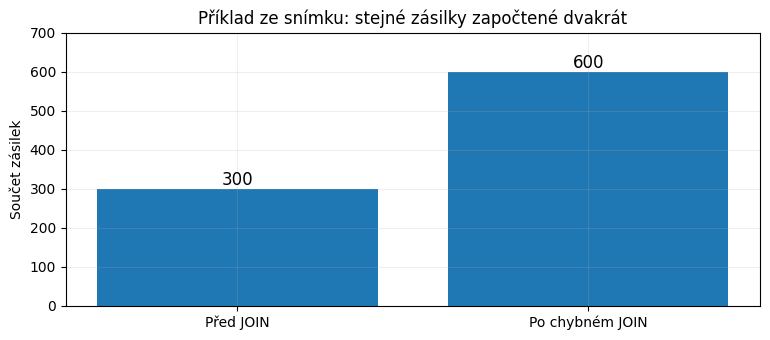

In [ ]:
fig, ax = plt.subplots(figsize=(7.8, 3.5))                              # vytvoří plátno pro graf s danou velikostí (šířka, výška) v palcích
values = [mini_provoz["zasilek"].sum(), mini_join["zasilek"].sum()]     # vytvoří seznam hodnot pro vykreslení
ax.bar(["Před JOIN", "Po chybném JOIN"], values)                        # vykreslí sloupcový graf s názvy osy x a hodnotami z listu values
ax.set_ylabel("Součet zásilek")
ax.set_title("Příklad ze snímku: stejné zásilky započtené dvakrát")
for i, v in enumerate(values):
    ax.text(i, v + 10, str(v), ha="center", fontsize=12)
ax.set_ylim(0, 700)                                                     # nastaví rozsah osy y, aby se texty nevešly mimo plátno
fig.tight_layout()                                                      # upraví okraje grafu, aby se texty nevešly mimo plátno
fig.savefig(OUT/"01_nasobeni_join.png", dpi=140)
plt.show()

### E2. Kontrola skutečného chybného číselníku B02

Výukový negativní test: používáme **záměrně chybný** číselník. Nejprve necháme `merge` proběhnout a změříme chybu; potom `validate="many_to_one"` chybu správně odmítne.

In [38]:
# kontrola, že při chybném JOINu se počet řádků a zásilek zdvojnásobí
pobocky_chybne = pd.read_csv(DATA/"reference"/"pobocky_chybny_ciselnik.csv",
                              sep=";", encoding="utf-8-sig", dtype="string", keep_default_na=False)

rozmnozene = opraveno.merge(pobocky_chybne, on="pobocka_id", how="left")                    # sloučení, které obsahuje duplicitní pobočky
print("Správně:", len(analyticka), "řádků /", analyticka.pocet_zasilek.sum(), "zásilek")    # výpis počtu řádků a součtu zásilek z analytické tabulky
print("Chybně: ", len(rozmnozene), "řádků /", rozmnozene.pocet_zasilek.sum(), "zásilek")    # výpis počtu řádků a součtu zásilek z chybných dat

assert (len(rozmnozene), rozmnozene.pocet_zasilek.sum()) == (168,77529)

try:
    opraveno.merge(pobocky_chybne, on="pobocka_id", how="left", validate="many_to_one")     # kontrola, že při sloučení je zachována kardinalita
except pd.errors.MergeError as err:
    print("SPRÁVNĚ ZACHYCENÁ CHYBA:", str(err))                                             # výpis chyby, která byla zachycena při sloučení
else:
    raise AssertionError("Očekávaná chyba kardinality nebyla odhalena")

pocet_shod = opraveno[["zaznam_id", "pobocka_id"]].merge(                                   # sloučení, aby se zjistilo, kolik řádků má shodné ID pobočky
    pobocky_chybne[["pobocka_id"]].assign(_shoda=1),
    on="pobocka_id", how="left"
).groupby("zaznam_id", as_index=False)["_shoda"].sum()

display(pocet_shod.head(6))
print("Počty shod na klíč:")
display(pocet_shod.groupby("_shoda", as_index=False).size())
assert (pocet_shod["_shoda"] == 2).sum() == 24

Správně: 144 řádků / 71284 zásilek
Chybně:  168 řádků / 77529 zásilek
SPRÁVNĚ ZACHYCENÁ CHYBA: Merge keys are not unique in right dataset; not a many-to-one merge

Duplicates in right:
 pobocka_id
       B02 ...


,zaznam_id,_shoda
0,R001,1
1,R002,1
2,R003,2
3,R004,2
4,R005,1
5,R006,1


Počty shod na klíč:


,_shoda,size
0,1,120
1,2,24


### E3. Složený klíč: měsíc + pobočka

Pokud je plán definován pro konkrétní **měsíc i pobočku**, propojení pouze podle pobočky přiřadí lednový plán také k únoru. Se správnou dvojicí klíčů vznikne přesně jedna shoda.

In [43]:
skutecnost = pd.DataFrame({
    "mesic": ["2025-01", "2025-02"], "pobocka_id": ["B01", "B01"],
    "skutecne": [100, 120]
})
plan = pd.DataFrame({
    "mesic": ["2025-01", "2025-02"], "pobocka_id": ["B01", "B01"],
    "plan": [105, 125]
})
print("\nSkutečnost vs. plán:")
display(skutecnost, plan)

spatne = skutecnost.merge(plan, on="pobocka_id", how="left")
spravne = skutecnost.merge(plan, on=["mesic", "pobocka_id"], how="left", validate="one_to_one")
print("\nChybný JOIN (pouze klíč pobočky):", len(spatne), "řádky")
display(spatne)

print("Správný JOIN (složený klíč měsíc + pobočka):", len(spravne), "řádky")
display(spravne)
assert len(spatne) == 4 and len(spravne) == 2


Skutečnost vs. plán:


,mesic,pobocka_id,skutecne
0,2025-01,B01,100
1,2025-02,B01,120


,mesic,pobocka_id,plan
0,2025-01,B01,105
1,2025-02,B01,125



Chybný JOIN (pouze klíč pobočky): 4 řádky


,mesic_x,pobocka_id,skutecne,mesic_y,plan
0,2025-01,B01,100,2025-01,105
1,2025-01,B01,100,2025-02,125
2,2025-02,B01,120,2025-01,105
3,2025-02,B01,120,2025-02,125


Správný JOIN (složený klíč měsíc + pobočka): 2 řádky


,mesic,pobocka_id,skutecne,plan
0,2025-01,B01,100,105
1,2025-02,B01,120,125


---
# F. Široká a dlouhá tabulka – Pivot / Unpivot (PL04)

Snímek *Dlouhá a široká podoba mají jiný účel* ukazuje přesun **měsíců z řádků do sloupců**. `pivot` nemusí snižovat informaci, pouze mění, co znamená jeden řádek. Důležitá kontrola je zachování hodnot a správná jedinečnost klíčů.

In [ ]:
# kontrola pivotování (pivot a melt)
dlouha_demo = pd.DataFrame({
    "pobocka_id": ["B01", "B01", "B02", "B02"],
    "mesic": ["2025-01", "2025-02", "2025-01", "2025-02"],
    "pocet": [100, 120, 80, 90]
})

siroka_demo = dlouha_demo.pivot(index="pobocka_id", columns="mesic", values="pocet").reset_index()
zpet_dlouha = siroka_demo.melt(
    id_vars="pobocka_id", var_name="mesic", value_name="pocet"
).sort_values(["pobocka_id", "mesic"]).reset_index(drop=True)

# výpisy
print("DLOUHÁ (4 řádky)")
display(dlouha_demo)
print("ŠIROKÁ (2 řádky)")
display(siroka_demo)
print("ZPĚT DLOUHÁ (4 řádky)")
display(zpet_dlouha)

assert len(dlouha_demo) == len(zpet_dlouha) == 4
assert len(siroka_demo) == 2
assert dlouha_demo["pocet"].sum() == siroka_demo.iloc[:,1:].to_numpy().sum() == 390
pd.testing.assert_frame_equal(
    dlouha_demo.sort_values(["pobocka_id", "mesic"]).reset_index(drop=True),
    zpet_dlouha,
    check_dtype=False
)

DLOUHÁ (4 řádky)


,pobocka_id,mesic,pocet
0,B01,2025-01,100
1,B01,2025-02,120
2,B02,2025-01,80
3,B02,2025-02,90


ŠIROKÁ (2 řádky)


mesic,pobocka_id,2025-01,2025-02
0,B01,100,120
1,B02,80,90


ZPĚT DLOUHÁ (4 řádky)


,pobocka_id,mesic,pocet
0,B01,2025-01,100
1,B01,2025-02,120
2,B02,2025-01,80
3,B02,2025-02,90


### F2. Graf pro široký formát – hodnoty podle měsíců a poboček

Široká matice se dobře hodí například pro tepelnou mapu (heatmap). Matplotlib použije stejné čtyři hodnoty; graf nepředstírá žádná další pozorování.

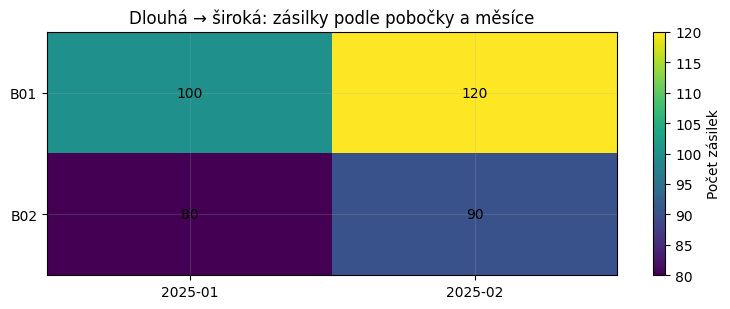

In [19]:
matice_demo = siroka_demo.set_index("pobocka_id")
fig, ax = plt.subplots(figsize=(7.8,3.2))
im = ax.imshow(matice_demo.to_numpy(dtype=float), aspect="auto")
ax.set_xticks(range(len(matice_demo.columns)), matice_demo.columns)
ax.set_yticks(range(len(matice_demo.index)), matice_demo.index)
ax.set_title("Dlouhá → široká: zásilky podle pobočky a měsíce")
for i in range(matice_demo.shape[0]):
    for j in range(matice_demo.shape[1]):
        ax.text(j, i, f"{matice_demo.iloc[i,j]:.0f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Počet zásilek")
fig.tight_layout()
fig.savefig(OUT/"02_siroka_tabulka_heatmap.png", dpi=140)
plt.show()

### F3. Široký/ dlouhý formát nad skutečnými daty PL04

Opravená datová sada obsahuje 144 řádků: 12 měsíců × 6 poboček × 2 služby. Vybereme jen `(měsíc, pobočka, služba, počet zásilek)` a převedeme **služby** `standard` a `expres` do sloupců: 144 → 72 řádků. Pak provedeme Unpivot zpět.

U `pivot()` musí být kombinace klíčů jedinečná; pokud není, dostaneme chybu. `pivot_table(aggfunc="sum")` by případy se stejným klíčem sečetl, ale to je správné jen při věcně oprávněné agregaci.

In [20]:
dlouha_sluzby = analyticka[["mesic","pobocka_id","sluzba","pocet_zasilek"]].copy()
assert not dlouha_sluzby.duplicated(["mesic","pobocka_id","sluzba"]).any()
siroka_sluzby = dlouha_sluzby.pivot(
    index=["mesic","pobocka_id"], columns="sluzba", values="pocet_zasilek"
).reset_index()
siroka_sluzby.columns.name = None
obnovena = siroka_sluzby.melt(
    id_vars=["mesic","pobocka_id"],
    value_vars=["standard","expres"],
    var_name="sluzba",value_name="pocet_zasilek"
)
print("Původní dlouhá:", dlouha_sluzby.shape,
      "| široká:", siroka_sluzby.shape, "| obnovená dlouhá:", obnovena.shape)
assert (len(dlouha_sluzby), len(siroka_sluzby), len(obnovena)) == (144, 72, 144)
assert (dlouha_sluzby.pocet_zasilek.sum() ==
        siroka_sluzby[["standard","expres"]].to_numpy().sum() ==
        obnovena.pocet_zasilek.sum() == 71284)
l = dlouha_sluzby.sort_values(["mesic","pobocka_id","sluzba"]).reset_index(drop=True)
r = obnovena.sort_values(["mesic","pobocka_id","sluzba"]).reset_index(drop=True)
pd.testing.assert_frame_equal(l,r,check_dtype=False)
display(siroka_sluzby.head(5))

Původní dlouhá: (144, 4) | široká: (72, 4) | obnovená dlouhá: (144, 4)


,mesic,pobocka_id,expres,standard
0,2025-01,B01,332,854
1,2025-01,B02,142,348
2,2025-01,B03,226,605
3,2025-01,B04,397,1025
4,2025-01,B05,87,260


### F4. `Unpivot` tří ukazatelů do sloupců `ukazatel` / `hodnota`

Jednotlivé ukazatele mají **různé jednotky** (počty zásilek, počty zpožděných, náklady v Kč). Dlouhý sloupec `hodnota` proto **nesmíme sečíst bez omezení na konkrétní ukazatel**. V pandas metoda `melt()` sama od sebe zachová i chybějící `NaN`; při požadavku na chování jako v Power Query je nutné `dropna()` uvést výslovně.

In [21]:
ukazatele_long = analyticka.melt(
    id_vars=["zaznam_id", "mesic", "pobocka_id", "sluzba"],
    value_vars=["pocet_zasilek", "pocet_zpozdenych", "naklady_kc"],
    var_name="ukazatel", value_name="hodnota"
)
assert len(ukazatele_long) == 144 * 3 == 432
print("Po převodu tří ukazatelů na řádky:", len(ukazatele_long))
display(ukazatele_long.head(8))
print("Součet pouze hodnot typu pocet_zasilek:",
      ukazatele_long.loc[ukazatele_long["ukazatel"].eq("pocet_zasilek"), "hodnota"].sum())

Po převodu tří ukazatelů na řádky: 432


,zaznam_id,mesic,pobocka_id,sluzba,ukazatel,hodnota
0,R001,2025-01,B01,standard,pocet_zasilek,854.0
1,R002,2025-01,B01,expres,pocet_zasilek,332.0
2,R003,2025-01,B02,standard,pocet_zasilek,348.0
3,R004,2025-01,B02,expres,pocet_zasilek,142.0
4,R005,2025-01,B03,standard,pocet_zasilek,605.0
5,R006,2025-01,B03,expres,pocet_zasilek,226.0
6,R007,2025-01,B04,standard,pocet_zasilek,1025.0
7,R008,2025-01,B04,expres,pocet_zasilek,397.0


Součet pouze hodnot typu pocet_zasilek: 71284.0


---
# G. Seskupení, součty a správná procenta (PL04 → PL06)

**Power Query:** *Seskupit podle* a přidat vlastní sloupec. **pandas:** `groupby().agg()` a pak podíl **součtu zpožděných / součtu zásilek**. Nikoli prostý průměr měsíčních procent.

In [22]:
souhrn_pobocek = (analyticka.groupby("pobocka_id", as_index=False)
    .agg(zasilek=("pocet_zasilek","sum"), zpozdenych=("pocet_zpozdenych","sum")))
souhrn_pobocek["podil"] = souhrn_pobocek["zpozdenych"] / souhrn_pobocek["zasilek"]
assert len(souhrn_pobocek) == 6
assert souhrn_pobocek["zasilek"].sum() == 71284
assert souhrn_pobocek["zpozdenych"].sum() == 2986
print("Celkový podíl zpoždění: {:.2%}".format(2986 / 71284))
display(souhrn_pobocek.assign(podil_procent=souhrn_pobocek["podil"]*100).round(3))

Celkový podíl zpoždění: 4.19%


,pobocka_id,zasilek,zpozdenych,podil,podil_procent
0,B01,16379,548,0.033,3.346
1,B02,6245,404,0.065,6.469
2,B03,11446,467,0.041,4.080
3,B04,19092,500,0.026,2.619
4,B05,4678,428,0.091,9.149
5,B06,13444,639,0.048,4.753


### G2. Vizualizace: stejné pobočky, dvě různá pořadí

Podle **absolutního počtu** zpožděných vede B06. Podle **relativního podílu** vede B05. Grafy mají samostatné osy a tituly; různý jmenovatel znamená jinou otázku.

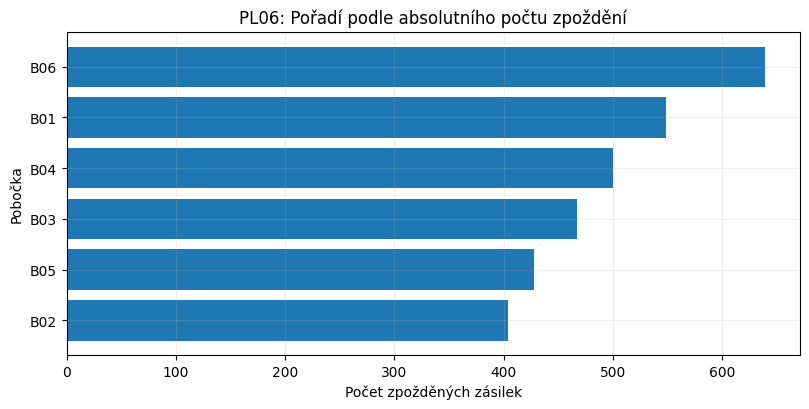

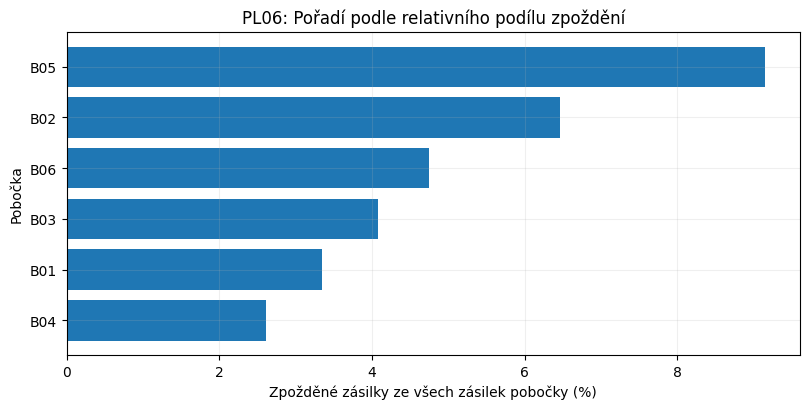

In [23]:
absolute = souhrn_pobocek.sort_values("zpozdenych")
fig, ax = plt.subplots(figsize=(8.2,4.2))
ax.barh(absolute["pobocka_id"], absolute["zpozdenych"])
ax.set_xlabel("Počet zpožděných zásilek")
ax.set_ylabel("Pobočka")
ax.set_title("PL06: Pořadí podle absolutního počtu zpoždění")
fig.tight_layout()
fig.savefig(OUT/"03_pobocky_absolutni.png", dpi=140)
plt.show()

relative = souhrn_pobocek.sort_values("podil")
fig, ax = plt.subplots(figsize=(8.2,4.2))
ax.barh(relative["pobocka_id"], relative["podil"]*100)
ax.set_xlabel("Zpožděné zásilky ze všech zásilek pobočky (%)")
ax.set_ylabel("Pobočka")
ax.set_title("PL06: Pořadí podle relativního podílu zpoždění")
fig.tight_layout()
fig.savefig(OUT/"04_pobocky_relativni.png", dpi=140)
plt.show()
assert absolute.iloc[-1].pobocka_id == "B06"
assert relative.iloc[-1].pobocka_id == "B05"

### G3. Časové trendy se správnou jednotkou

Agregujeme po měsících. Zobrazíme zvlášť vývoj objemu zásilek a zvlášť vývoj zpožděnosti – dva různě definované ukazatele nemícháme na dvojí ose bez vysvětlení.

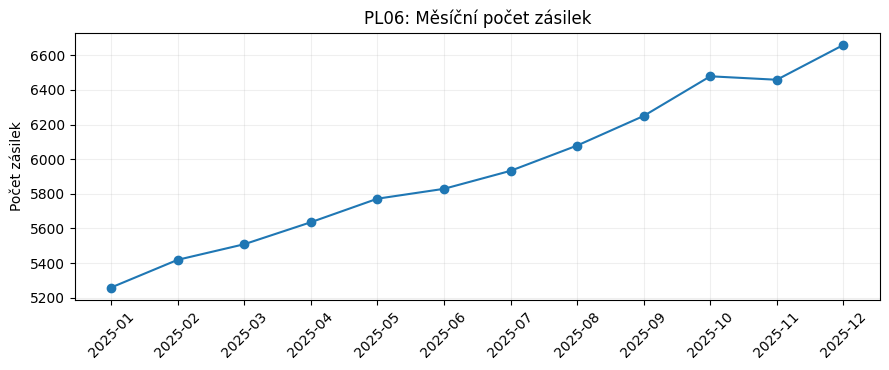

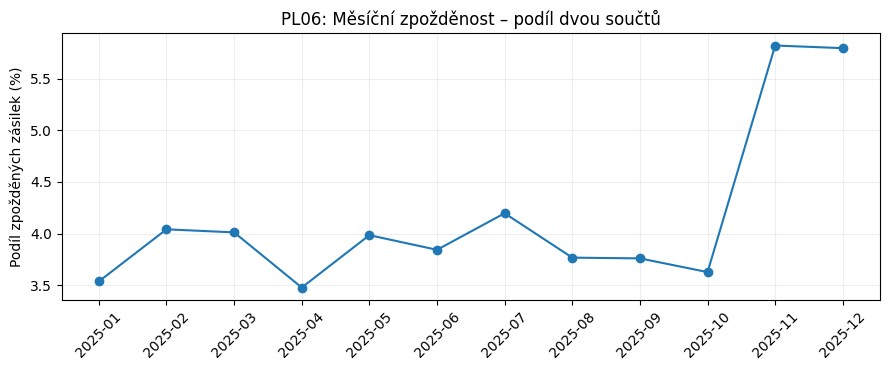

In [24]:
souhrn_mesicu = (analyticka.groupby("mesic", as_index=False)
    .agg(zasilek=("pocet_zasilek","sum"),zpozdenych=("pocet_zpozdenych","sum")))
souhrn_mesicu["podil"] = souhrn_mesicu["zpozdenych"]/souhrn_mesicu["zasilek"]
souhrn_mesicu = souhrn_mesicu.sort_values("mesic")
assert len(souhrn_mesicu) == 12
fig, ax = plt.subplots(figsize=(9,3.8))
ax.plot(souhrn_mesicu["mesic"], souhrn_mesicu["zasilek"], marker="o")
ax.set_ylabel("Počet zásilek")
ax.set_title("PL06: Měsíční počet zásilek")
ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout(); fig.savefig(OUT/"05_mesicni_zasilky.png", dpi=140); plt.show()
fig, ax = plt.subplots(figsize=(9,3.8))
ax.plot(souhrn_mesicu["mesic"], souhrn_mesicu["podil"]*100, marker="o")
ax.set_ylabel("Podíl zpožděných zásilek (%)")
ax.set_title("PL06: Měsíční zpožděnost – podíl dvou součtů")
ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout(); fig.savefig(OUT/"06_mesicni_podil.png", dpi=140); plt.show()

### G4. Vážený versus nevážený průměr procent

Malý původní model PL06: A má 10/100 = 10 %, B má 18/900 = 2 %. Prostý průměr procent 6 % odpovídá otázce „jaký je průměr dvou stejně vážených poboček“; celkový podíl ze všech zásilek je 28/1000 = **2,8 %**.

In [25]:
model_ab = pd.read_csv(DATA/"reference"/"vazeny_podil.csv", sep=";", encoding="utf-8-sig")
model_ab["podil"] = model_ab["pocet_zpozdenych"] / model_ab["pocet_zasilek"]
prosty = model_ab["podil"].mean()
vazeny = model_ab["pocet_zpozdenych"].sum()/model_ab["pocet_zasilek"].sum()
display(model_ab)
print(f"Prostý průměr podílů: {prosty:.1%}; podíl všech zásilek: {vazeny:.1%}")
assert np.isclose(prosty, 0.06) and np.isclose(vazeny,0.028)

,pobocka,pocet_zasilek,pocet_zpozdenych,podil
0,A,100,10,0.10
1,B,900,18,0.02


Prostý průměr podílů: 6.0%; podíl všech zásilek: 2.8%


### G5. Simpsonův paradox – rozdílné skladby skupin

Podíváme se na úspěšnost dvou týmů podle obtížnosti a celkově. B je lepší ve dvou dílčích kategoriích, avšak A má lepší **skutečný souhrn** kvůli většímu podílu lehkých úloh. To není důkaz „lepšího týmu“ bez upřesnění srovnávací otázky.

,tym,typ_ulohy,uspechy,celkem,uspesnost
0,A,snadné,90,100,0.90
1,A,obtížné,24,40,0.60
2,B,snadné,19,20,0.95
3,B,obtížné,140,200,0.70


,tym,uspechy,pokusy,uspesnost
0,A,114,140,0.814286
1,B,159,220,0.722727


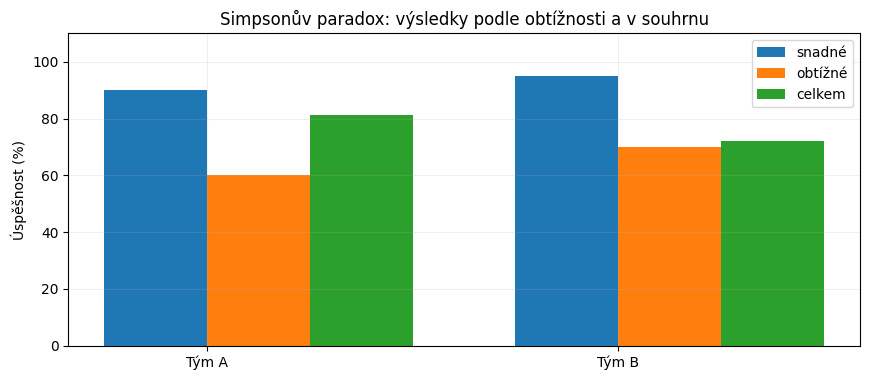

In [26]:
simpson = pd.read_csv(DATA/"reference"/"simpson.csv",sep=";",encoding="utf-8-sig")
simpson["uspesnost"] = simpson["uspechy"] / simpson["celkem"]
celky_tymu = simpson.groupby("tym",as_index=False).agg(uspechy=("uspechy","sum"),pokusy=("celkem","sum"))
celky_tymu["uspesnost"] = celky_tymu["uspechy"]/celky_tymu["pokusy"]
display(simpson, celky_tymu)
assert np.isclose(celky_tymu.set_index("tym").loc["A","uspesnost"], 114/140)
assert np.isclose(celky_tymu.set_index("tym").loc["B","uspesnost"], 159/220)

fig, ax = plt.subplots(figsize=(8.8,3.9))
xs = np.arange(2)
width = 0.25
s = simpson.set_index(["tym","typ_ulohy"])
labels = ["snadné", "obtížné"]
for j, typ in enumerate(labels):
    ax.bar(xs+(j-0.5)*width, [s.loc[(t,typ),"uspesnost"]*100 for t in ["A","B"]], width, label=typ)
ax.bar(xs+1.5*width, celky_tymu.set_index("tym").loc[["A","B"],"uspesnost"]*100,
       width, label="celkem")
ax.set_xticks(xs,["Tým A","Tým B"])
ax.set_ylim(0,110)
ax.set_ylabel("Úspěšnost (%)")
ax.legend(loc="upper right")
ax.set_title("Simpsonův paradox: výsledky podle obtížnosti a v souhrnu")
fig.tight_layout();fig.savefig(OUT/"07_simpsonuv_paradox.png",dpi=140);plt.show()

---
# H. Základní statistika a vizualizace (PL05)

Samostatný soubor `doby_doruceni.csv` obsahuje **240 individuálních dob** v hodinách. Nemá vazbu na pobočky. **Nespojujeme jej s provozní tabulkou podle pořadí řádků** a netvrdíme, že jde o statisticky reprezentativní vzorek všech 71 284 zásilek.

In [27]:
doby = pd.read_csv(DATA/"reference"/"doby_doruceni.csv",
                   sep=";",encoding="utf-8-sig",decimal=",")
serie = doby["doba_hodin"]
q1,q3 = serie.quantile([.25,.75],interpolation="linear")
iqr = q3-q1
mez_d = q1-1.5*iqr
mez_h = q3+1.5*iqr
odlehle = doby.loc[(serie < mez_d) | (serie > mez_h)]
statistiky = pd.Series({
    "počet": len(serie), "min h": serie.min(), "max h": serie.max(),
    "průměr h": serie.mean(), "medián h": serie.median(),
    "Q1 h": q1, "Q3 h": q3, "IQR h": iqr,
    "výběrová odchylka h": serie.std(ddof=1),
    "dolní mez h": mez_d, "horní mez h": mez_h,
    "počet IQR odlehlých":len(odlehle)
})
display(statistiky.to_frame("Hodnota"), odlehle)
assert len(serie) == 240
assert np.isclose(serie.mean(),31.929583333333333)
assert np.isclose(q1,18.9) and np.isclose(q3,37.075)
assert len(odlehle) == 13

,Hodnota
počet,240.000000
min h,8.500000
max h,240.000000
průměr h,31.929583
medián h,27.550000
Q1 h,18.900000
Q3 h,37.075000
IQR h,18.175000
výběrová odchylka h,21.555653
dolní mez h,-8.362500


,mereni_id,doba_hodin
16,M017,67.0
21,M022,114.7
65,M066,92.2
94,M095,71.2
102,M103,74.9
122,M123,87.2
156,M157,67.2
172,M173,69.5
197,M198,76.5
206,M207,92.5


### H2. Dva histogramy: 10hodinové a 20hodinové intervaly

Použijeme stejný rozsah **0–260 hodin**, stejné vstupní hodnoty a hranice `[0,10), [10,20), ...`. Rozdíl je jen v šířce intervalu; součet četností obou histogramů musí být 240.

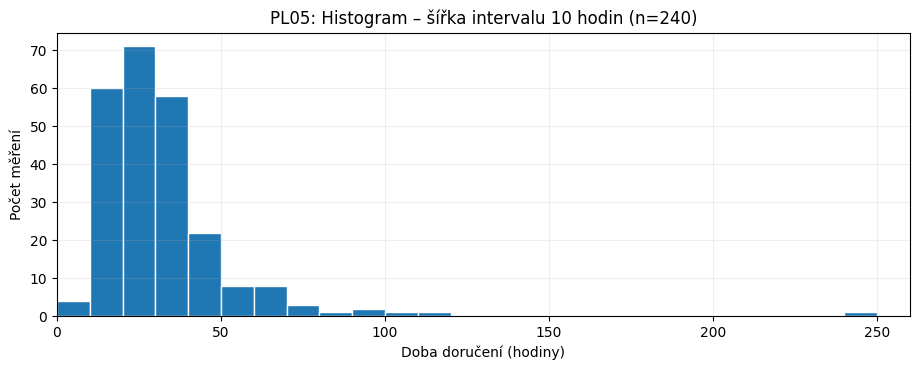

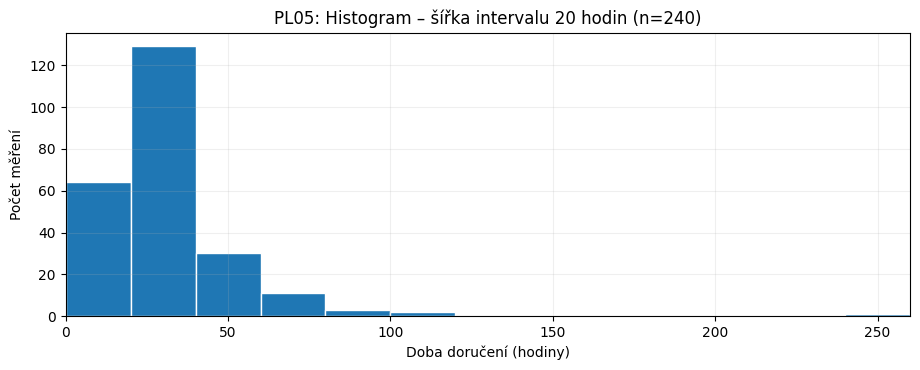

In [28]:
for sirka in (10, 20):
    hranice = np.arange(0, 260 + sirka, sirka)
    pocty, _ = np.histogram(serie, bins=hranice)
    assert pocty.sum() == 240
    fig, ax = plt.subplots(figsize=(9.3,3.8))
    ax.hist(serie, bins=hranice, edgecolor="white")
    ax.set_xlim(0,260)
    ax.set_xlabel("Doba doručení (hodiny)")
    ax.set_ylabel("Počet měření")
    ax.set_title(f"PL05: Histogram – šířka intervalu {sirka} hodin (n=240)")
    fig.tight_layout()
    fig.savefig(OUT/f"08_histogram_{sirka}h.png",dpi=140)
    plt.show()

### H3. Boxplot a analýza citlivosti na jediný případ M240

Boxplot pomáhá popsat kvartily a potenciální odlehlé případy. **IQR práh není důkaz chybného měření.** Původních 240 hodnot zůstává zachováno; pouze vytvoříme oddělenou výukovou variantu bez konkrétního ID `M240`. Nemažeme všech 13 označených případů.

,ukazatel,všechna měření,bez M240
0,počet,240.000000,239.000000
1,průměr (h),31.929583,31.058996
2,medián (h),27.550000,27.500000


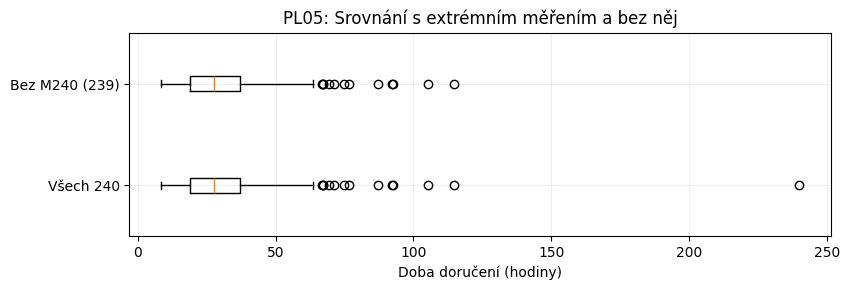

In [29]:
bez_m240 = doby.loc[doby["mereni_id"] != "M240", "doba_hodin"]
assert len(bez_m240)==239
assert (doby.loc[doby["mereni_id"]=="M240","doba_hodin"]==240).all()
srovnani = pd.DataFrame({
    "ukazatel":["počet", "průměr (h)", "medián (h)"],
    "všechna měření":[len(serie),serie.mean(),serie.median()],
    "bez M240":[len(bez_m240),bez_m240.mean(),bez_m240.median()]
})
display(srovnani)
assert np.isclose(bez_m240.mean(),31.05899581589958)
assert np.isclose(bez_m240.median(),27.50)
fig, ax=plt.subplots(figsize=(8.6,3.0))
ax.boxplot([serie,bez_m240],vert=False)
ax.set_yticks([1,2],["Všech 240","Bez M240 (239)"])
ax.set_xlabel("Doba doručení (hodiny)")
ax.set_title("PL05: Srovnání s extrémním měřením a bez něj")
fig.tight_layout();fig.savefig(OUT/"09_boxplot_citlivost.png",dpi=140);plt.show()

---
# I. Kontrolní protokol, exporty a úkoly k samostatné práci

V profesionálním postupu musí být výsledek **reprodukovatelný**. Vytvoříme souhrnný kontrolní protokol a datové exporty, ale **nikdy nepřepíšeme vstupy ve složce `data/`**.

In [30]:
protokol = {
    "raw_rows": int(len(raw)),
    "raw_columns": int(raw.shape[1]),
    "monthly_files": int(len(files)),
    "monthly_equal_as_multiset": bool(multisouborovy_podpis(raw)==multisouborovy_podpis(monthly)),
    "exact_duplicate_extra_rows": int(len(kopie)),
    "unique_raw_rows":int(len(bez_kopii)),
    "pre_repair_valid":int(len(validni)),
    "pre_repair_quarantine":int(len(karantena)),
    "documented_repairs":int(len(opravy)),
    "final_rows":int(len(analyticka)),
    "shipments":int(analyticka.pocet_zasilek.sum()),
    "delayed":int(analyticka.pocet_zpozdenych.sum()),
    "wrong_lookup_join_rows":int(len(rozmnozene)),
    "wrong_lookup_shipments":int(rozmnozene.pocet_zasilek.sum()),
    "wide_rows_after_service_pivot":int(len(siroka_sluzby)),
    "long_rows_after_melt":int(len(obnovena)),
    "individual_times":int(len(doby)),
    "iqr_flagged_times":int(len(odlehle))
}
(OUT/"kontrolni_protokol.json").write_text(json.dumps(protokol,indent=2,ensure_ascii=False),encoding="utf-8")
analyticka.to_csv(OUT/"analyticka.csv",sep=";",decimal=",",encoding="utf-8-sig",index=False)
souhrn_pobocek.to_csv(OUT/"souhrn_pobocek.csv",sep=";",decimal=",",encoding="utf-8-sig",index=False)
siroka_sluzby.to_csv(OUT/"wide_sluzby.csv",sep=";",decimal=",",encoding="utf-8-sig",index=False)
karantena.assign(duvody=karantena["duvody"].map("; ".join)).to_csv(
    OUT/"karantena_pred_opravou.csv",sep=";",decimal=",",encoding="utf-8-sig",index=False)
print(json.dumps(protokol,indent=2,ensure_ascii=False))
print("Výstupy byly uloženy do:", OUT.resolve())

{
  "raw_rows": 149,
  "raw_columns": 7,
  "monthly_files": 12,
  "monthly_equal_as_multiset": true,
  "exact_duplicate_extra_rows": 5,
  "unique_raw_rows": 144,
  "pre_repair_valid": 136,
  "pre_repair_quarantine": 8,
  "documented_repairs": 8,
  "final_rows": 144,
  "shipments": 71284,
  "delayed": 2986,
  "wrong_lookup_join_rows": 168,
  "wrong_lookup_shipments": 77529,
  "wide_rows_after_service_pivot": 72,
  "long_rows_after_melt": 144,
  "individual_times": 240,
  "iqr_flagged_times": 13
}
Výstupy byly uloženy do: /mnt/data/PL04_Python_Notebook_work/Power_Query_v_Pythonu/vystupy


## Úkoly (s kontrolou výsledků)

1. **JOIN:** Změňte příklad D2 na spojení podle jiné hodnoty. Předpovězte počty řádků pro všech šest typů a až potom spusťte kód.
2. **Negativní test:** V chybném číselníku B02 najděte všechny provozní záznamy, které mají dvě shody. Zdůvodněte, proč je jich 24.
3. **Pivot:** Ověřte vlastními dvěma způsoby, že součet 71 284 zůstává stejný před převodem 144 → 72 → 144.
4. **Unpivot:** U tabulky ukazatelů zjistěte, proč nelze bez rozlišení jednotky sčítat `naklady_kc` a `pocet_zasilek`.
5. **Procenta:** Seřaďte B01 až B06 podle absolutního počtu a podle relativního podílu. Která pobočka vede v každém případě a proč?
6. **Histogram:** Porovnejte intervaly 10 h a 20 h. Vysvětlete, proč nesmíme oříznout osu před hodnotou 240 h bez upozornění.
7. **Interpretace:** Napište dvě věty, které lze z dat prokázat, a dvě hypotézy, které by vyžadovaly nové informace.

**Výstup:** notebook s provedenými buňkami, 2–3 vybrané grafy a krátký komentář. Pro odevzdání přiložte `vystupy/kontrolni_protokol.json`.

**Řešení:** Bilance PL03: `149 = 5 + 136 + 8`; po opravách 144 řádků; platný součet 71 284; chybné spojení 168 řádků / 77 529; Pivot služeb 144 → 72 → 144; B06 vede absolutním počtem, B05 relativním podílem; IQR označí 13 dob, ale srovnání bez M240 vynechává pouze 1 měření.

## Poznámky k přesnosti, verzím a interpretaci

- **Power Query vs pandas:** `pandas.melt()` standardně zachová `NaN`; pokud chcete pouze pozorované hodnoty, použijte `dropna(subset=["hodnota"])`. Power Query při Unpivot hodnoty `null` nemusí přidat jako samostatné výstupní řádky.
- **Join:** `merge(validate="many_to_one")` ověřuje kardinalitu pravého klíče, avšak nenahrazuje kontrolu úplnosti. Pro to je zde `indicator=True`.
- **Pivot:** `pivot()` vyžaduje jednoznačné klíče. `pivot_table(aggfunc="sum")` může duplicitní kombinace sčítat; to je správné jen tehdy, když to odpovídá smyslu dat.
- **Chybějící čísla:** `NaN` není nula. Opravy jsou dovoleny jen s dokladem a mají vlastní audit.
- **Grafy:** zobrazení podílu se vypočítává *po* agregaci z čitatelů a jmenovatelů, ne jako průměr procent bez vah.
- **Rozsah výsledků:** všechny údaje jsou syntetické. Neodvozujte z nich závěry o skutečných organizacích.

**Další informace:** [pandas – merging](https://pandas.pydata.org/docs/user_guide/merging.html), [pandas – reshaping](https://pandas.pydata.org/docs/user_guide/reshaping.html), [Matplotlib – histogram](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html).